<a href="https://colab.research.google.com/github/khacbac/nlp/blob/main/ActivationFunction_GradientDescent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction
In this notebook, I will set up and draw graph for each Activation function and it's derivation, included ReLU, Sigmoid, LeakyReLU, Tanh, Swish...
Beside, I create a set_ax_style for each plot to use many times

Besides, we also visualize the **gradient descent 2D and 3D**




# Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Set style for plot

In [ ]:
def set_ax_style(xmin, xmax, ymin, ymax, ax):
  ax.set_frame_on(False)
  ax.axhline(y = 0, xmin = xmin, xmax = xmax, color='black')
  ax.axvline(x = 0, ymin = ymin, ymax = ymax, color='black')
  ax.set_xticks([xmin, xmax])
  ax.spines['left'].set_position('center')
  ax.set_yticks([ymin, ymax])

x = np.linspace(-10, 10, 100)

# ReLU

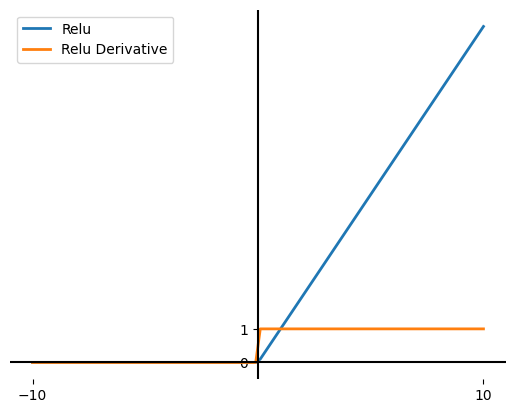

In [ ]:
def relu(x):
  f = np.maximum(0, x)
  dr = np.where(x > 0, 1, 0)
  return (f, dr)

y, dr = relu(x)

fig, ax = plt.subplots()
ax.plot(x, y, linewidth = 2.0, label = "Relu")
ax.plot(x, dr, linewidth = 2.0, label = "Relu Derivative")
ax.legend()
set_ax_style(-10, 10, 0, 1, ax)
plt.show()

# Sigmoid

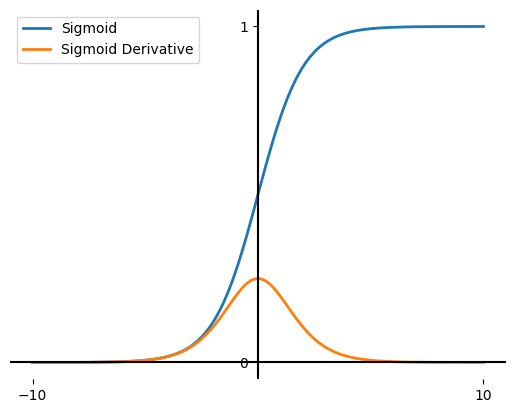

In [ ]:
def sigmoid(x):
  f = 1 / (1 + np.exp(-x))
  dr = f * (1 - f)
  return (f, dr)

y, dr = sigmoid(x)

fig, ax = plt.subplots()
ax.plot(x, y, linewidth = 2.0, label = "Sigmoid")
ax.plot(x, dr, linewidth = 2.0, label = "Sigmoid Derivative")
ax.legend()
set_ax_style(-10, 10, 0, 1, ax)
plt.show()

# Leaky ReLU
How to choose α:
1. Start with α = 0.01, as it's commonly used and works well in most cases.
2. Try higher values (e.g., α = 0.1) if you're dealing with very deep networks and need faster learning.
3. Use smaller values (e.g., α = 0.001) for more stable training in certain tasks, especially if the model becomes unstable.
4. Tune α through hyperparameter optimization (e.g., grid search or random search) to find the best value for your specific task.

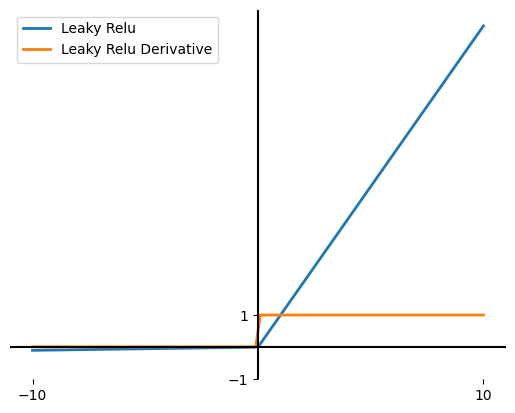

In [ ]:
def leaky_relu(x, alpha = 0.01):
  f = np.where(x > 0, x, alpha * x)
  dr = np.where(x > 0, 1, alpha)
  return (f, dr)

y, dr = leaky_relu(x)
fig, ax = plt.subplots()
ax.plot(x, y, linewidth = 2.0, label = "Leaky Relu")
ax.plot(x, dr, linewidth = 2.0, label = "Leaky Relu Derivative")
set_ax_style(-10, 10, -1, 1, ax)
ax.legend()
plt.show()

# Tanh

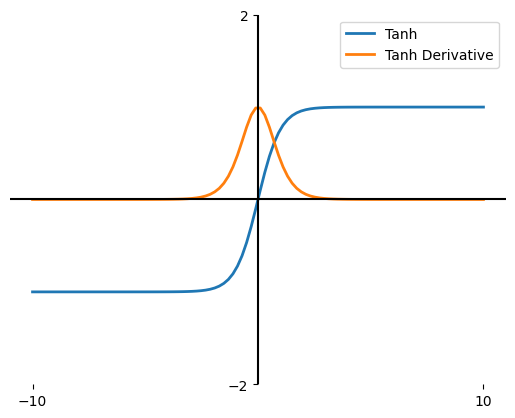

In [ ]:
def tanh(x):
  f = 2 / (1 + np.exp(-2*x)) - 1
  # f = (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x)
  dr = 1 - f**2
  return (f, dr)

y, dr = tanh(x)
fig, ax = plt.subplots()
ax.plot(x, y, linewidth = 2.0, label = "Tanh")
ax.plot(x, dr, linewidth = 2.0, label = "Tanh Derivative")
ax.legend()
set_ax_style(-10, 10, -2, 2, ax)
plt.show()

# Elu
1. Start with α = 1: This is the most commonly used value and works well in many cases.
2. Experiment with α: Try values such as 0.1 or 2 if the training is too slow or if the negative part of the function isn't contributing enough.
3. Tune α via optimization: You can perform hyperparameter optimization (e.g., grid search) to find the best value.

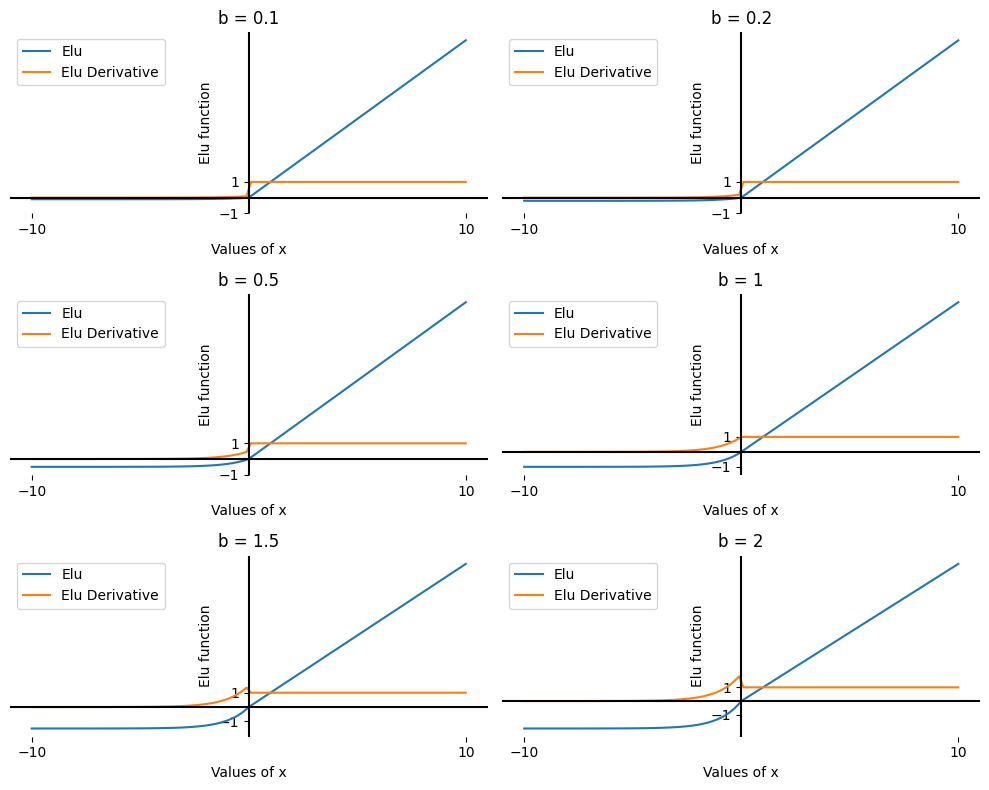

In [ ]:
def elu(x, alpha = 1):
  f = np.where(x >= 0, x, alpha * (np.exp(x) - 1))
  dr = np.where(x >= 0, 1, alpha * np.exp(x))
  return (f, dr)

b_list = [0.1,0.2,0.5,1,1.5,2]
fig, ax = plt.subplots(3,2, figsize = (10,8))
ax = ax.ravel()
for i,b in enumerate(b_list):
  y, dr = elu(x, b)
  ax[i].plot(x, y, label='Elu')
  ax[i].plot(x, dr, label='Elu Derivative')
  ax[i].set_title(f'b = {b}')
  ax[i].set_xlabel('Values of x')
  ax[i].set_ylabel('Elu function')
  ax[i].legend()
  set_ax_style(-10, 10, -1, 1, ax[i])

plt.tight_layout()
plt.show()

# Maxout
Maxout is an activation function that **outputs the maximum value from multiple linear functions**. It allows the network to learn more complex, piecewise linear functions compared to ReLU, which helps avoid the "dying neuron" problem where neurons stop updating. Maxout is **flexible**, making it useful for deep neural networks to model **non-linear relationships** in data. It can be especially effective in scenarios requiring more complex activation behavior than traditional ReLU.

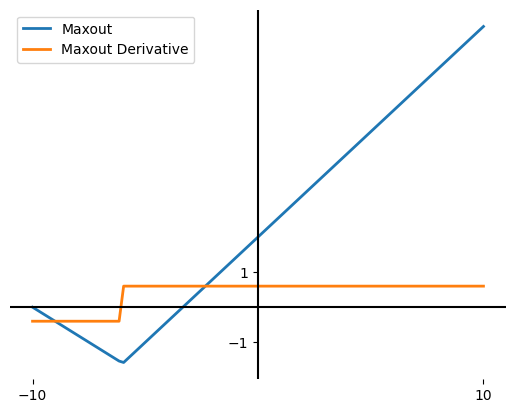

In [ ]:
w1 = 0.6
w2 = -0.4
b1 = 2
b2 = -4

def maxout(x):
  f = np.maximum(w1 * x + b1, w2 * x + b2)
  dr = np.where(f == w1 * x + b1, w1, w2)
  return (f, dr)

fig, ax = plt.subplots()
y, dr = maxout(x)
ax.plot(x, y, linewidth = 2.0, label = "Maxout")
ax.plot(x, dr, linewidth = 2.0, label = "Maxout Derivative")

ax.legend()
set_ax_style(-10, 10, -1, 1, ax)
plt.show()

# Swish
1. b=1: Standard Swish, good starting point.
2. Smaller b: Swish approaches Sigmoid (smoother transition).
3. Larger b: Swish approaches ReLU (sharper transition, faster learning).
4. Optimal b: Depends on the task/dataset; tune using hyperparameter optimization.

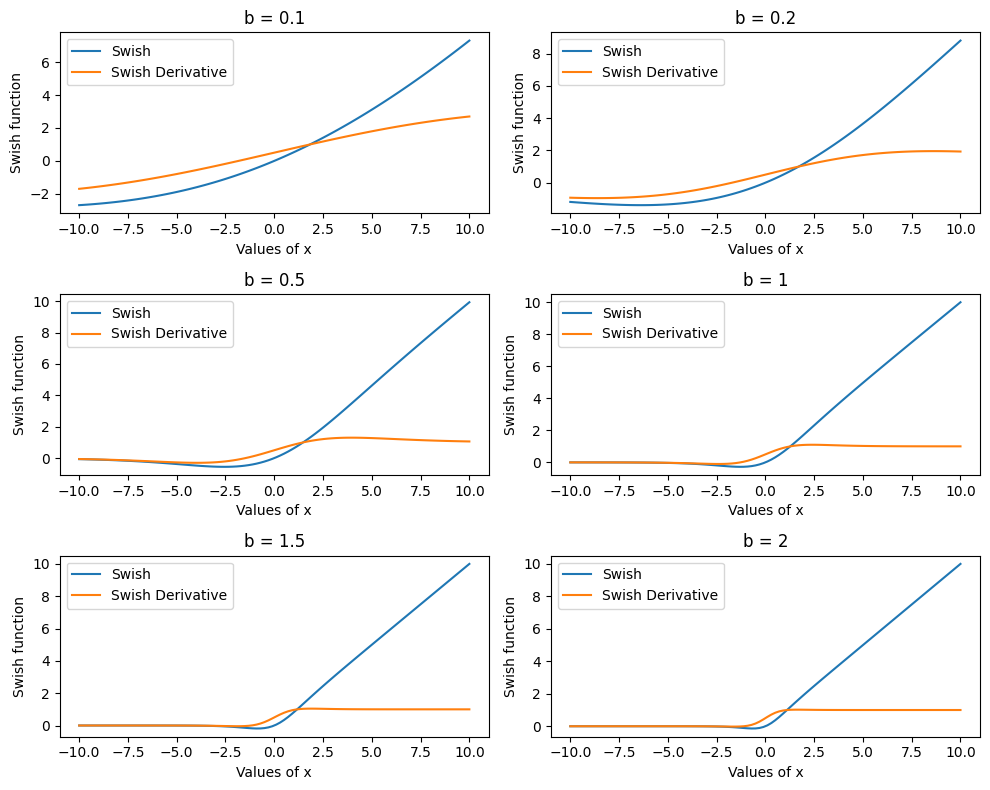

In [ ]:
def swish(x, b):
  f = x*sigmoid(b*x)[0]
  dr = f + sigmoid(b*x)[0]*(1-f)
  return f, dr

b_list = [0.1,0.2,0.5,1,1.5,2]
fig, ax = plt.subplots(3,2, figsize = (10,8))
ax = ax.ravel()
for i,b in enumerate(b_list):
  y, dr = swish(x, b)
  ax[i].plot(x, y, label='Swish')
  ax[i].plot(x, dr, label='Swish Derivative')
  ax[i].set_title(f'b = {b}')
  ax[i].set_xlabel('Values of x')
  ax[i].set_ylabel('Swish function')
  ax[i].legend()

plt.tight_layout()
plt.show()

#Gradient Descent 2D



In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Gradient và cost function
def grad(x):
    return 2*x + 5*np.cos(x)

def cost(x):
    return x**2 + 5*np.sin(x)

def GD(lr, x0, max_iter=50):
    x = x0
    history = []
    for it in range(max_iter):
        g = grad(x)
        c = cost(x)
        history.append((it, x, c, g))
        x_new = x - lr * g
        if abs(g) < 1e-3:  # điều kiện dừng
            break
        x = x_new
    return history

history1 = GD(0.1, -5, max_iter=50)
history2 = GD(0.1, 5, max_iter=50)

print("Gradient with x = -5\n")
for it, x, c, g in history1:
    print(f"iter {it}, x = {x:.4f}, cost = {c:.4f}, grad = {g:.4f}")
print("\nGradient with x = 5\n")
for it, x, c, g in history2:
    print(f"iter {it}, x = {x:.4f}, cost = {c:.4f}, grad = {g:.4f}")


Gradient with x = -5

iter 0, x = -5.0000, cost = 29.7946, grad = -8.5817
iter 1, x = -4.1418, cost = 21.3628, grad = -10.9842
iter 2, x = -3.0434, cost = 8.7723, grad = -11.0627
iter 3, x = -1.9371, cost = -0.9157, grad = -5.6653
iter 4, x = -1.3706, cost = -3.0216, grad = -1.7470
iter 5, x = -1.1959, cost = -3.2225, grad = -0.5610
iter 6, x = -1.1398, cost = -3.2436, grad = -0.1908
iter 7, x = -1.1207, cost = -3.2461, grad = -0.0663
iter 8, x = -1.1141, cost = -3.2464, grad = -0.0233
iter 9, x = -1.1118, cost = -3.2464, grad = -0.0082
iter 10, x = -1.1110, cost = -3.2464, grad = -0.0029
iter 11, x = -1.1107, cost = -3.2464, grad = -0.0010
iter 12, x = -1.1106, cost = -3.2464, grad = -0.0004

Gradient with x = 5

iter 0, x = 5.0000, cost = 20.2054, grad = 11.4183
iter 1, x = 3.8582, cost = 11.6014, grad = 3.9460
iter 2, x = 3.4636, cost = 10.4141, grad = 2.1841
iter 3, x = 3.2452, cost = 10.0141, grad = 1.5171
iter 4, x = 3.0934, cost = 9.8101, grad = 1.1927
iter 5, x = 2.9742, cost =

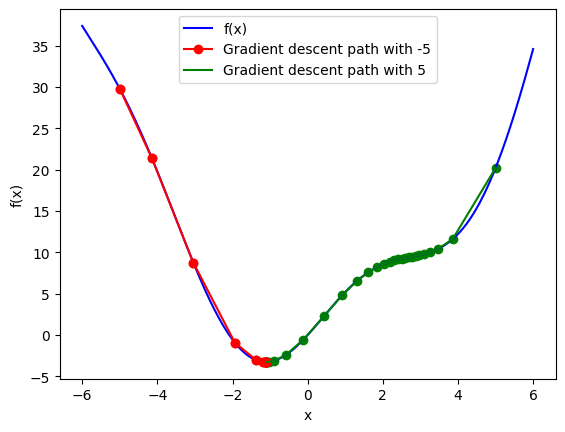

In [ ]:
# vẽ đồ thị cost function
X = np.linspace(-6, 6, 400)
Y = cost(X)

plt.plot(X, Y, 'b', label="f(x)")
plt.xlabel("x")
plt.ylabel("f(x)")

# vẽ các điểm gradient descent
xs = [h[1] for h in history1]
cs = [h[2] for h in history1]

xs2 = [h[1] for h in history2]
cs2 = [h[2] for h in history2]

plt.scatter(xs, cs, c='red')
plt.scatter(xs2, cs2, c='green')

plt.plot(xs, cs, 'ro-', label="Gradient descent path with -5")
plt.plot(xs2, cs2, label="Gradient descent path with 5", c='green')

plt.legend()
plt.show()


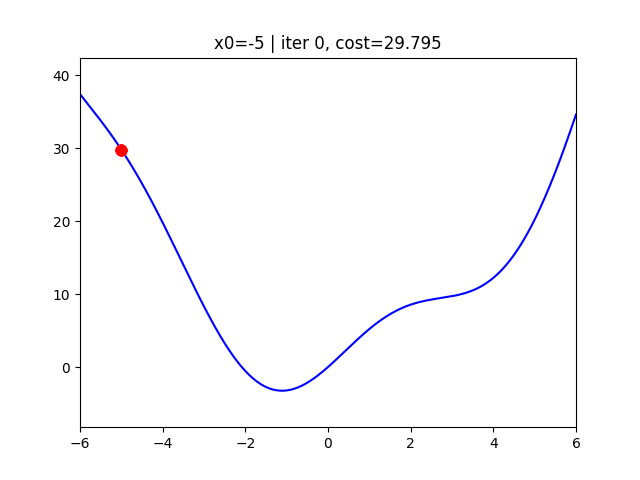

In [ ]:
from IPython.display import Image

fig1, ax1 = plt.subplots()
plt.close(fig1)   # tránh ảnh tĩnh

ax1.plot(X, Y, 'b', label="f(x)")
line1, = ax1.plot([], [], 'ro-', markersize=8)  # đỏ
ax1.set_xlim(-6, 6)
ax1.set_ylim(min(Y)-5, max(Y)+5)

xs1 = [h[1] for h in history1]
cs1 = [h[2] for h in history1]

def init1():
    line1.set_data([], [])
    return line1,

def update1(frame):
    line1.set_data(xs1[:frame+1], cs1[:frame+1])
    ax1.set_title(f"x0=-5 | iter {frame}, cost={cs1[frame]:.3f}")
    return line1,

ani1 = animation.FuncAnimation(fig1, update1, frames=len(xs1), init_func=init1,
                               blit=True, interval=400, repeat=False)
ani1.save("gd1.gif", writer="pillow")
Image(filename="gd1.gif")

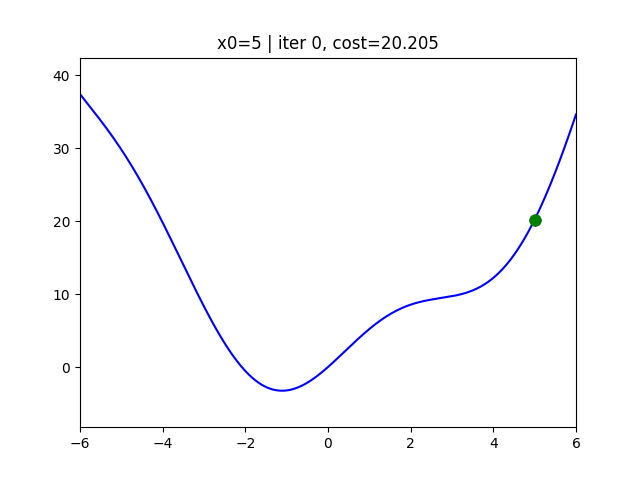

In [ ]:
fig2, ax2 = plt.subplots()
plt.close(fig2)   # tránh ảnh tĩnh

ax2.plot(X, Y, 'b', label="f(x)")
line2, = ax2.plot([], [], 'go-', markersize=8)  # xanh (green)
ax2.set_xlim(-6, 6)
ax2.set_ylim(min(Y)-5, max(Y)+5)

xs2 = [h[1] for h in history2]
cs2 = [h[2] for h in history2]

def init2():
    line2.set_data([], [])
    return line2,

def update2(frame):
    line2.set_data(xs2[:frame+1], cs2[:frame+1])
    ax2.set_title(f"x0=5 | iter {frame}, cost={cs2[frame]:.3f}")
    return line2,

ani2 = animation.FuncAnimation(fig2, update2, frames=len(xs2), init_func=init2,
                               blit=True, interval=200, repeat=False)
ani2.save("gd2.gif", writer="pillow")
Image(filename="gd2.gif")

# Gradient Descent 3D

**Import & định nghĩa hàm cost, gradient**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# cost function
def cost(theta0, theta1):
    return theta0**2 + theta1**2 + np.sin(3*theta0)*np.cos(2*theta1)

# gradient
def grad(theta0, theta1):
    dtheta0 = 2*theta0 + 3*np.cos(3*theta0)*np.cos(2*theta1)
    dtheta1 = 2*theta1 - 2*np.sin(3*theta0)*np.sin(2*theta1)
    return dtheta0, dtheta1

def GD_3D(lr=0.05, theta0=0.9, theta1=0.9, max_iter=50):
    history = []
    for it in range(max_iter):
        c = cost(theta0, theta1)
        history.append((theta0, theta1, c, it)) # Added iteration number to history
        g0, g1 = grad(theta0, theta1)
        theta0 -= lr * g0
        theta1 -= lr * g1
        if np.linalg.norm([g0, g1]) < 1e-3:
            break
    return history

history = GD_3D()

**Visualize 3D**

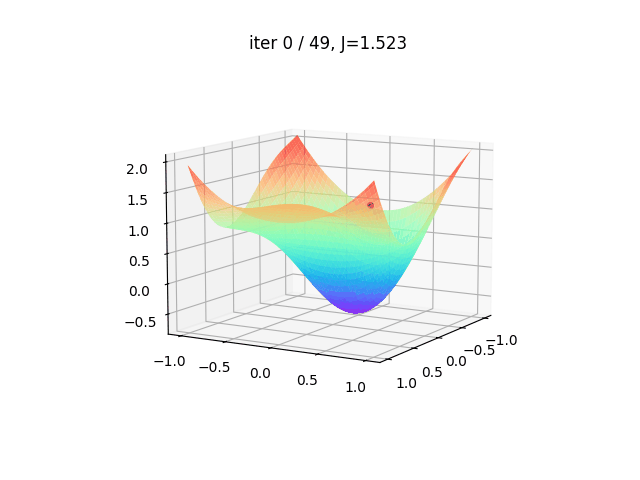

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import Image
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

# Tạo lưới surface
t0 = np.linspace(-1, 1, 100)
t1 = np.linspace(-1, 1, 100)
T0, T1 = np.meshgrid(t0, t1)
Z = cost(T0, T1)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
plt.close(fig)

# Vẽ surface
ax.plot_surface(T0, T1, Z, cmap="rainbow", alpha=0.7)

# Vẽ đường đi
line, = ax.plot([], [], 'ko-', markersize=4)

theta0s = [h[0] for h in history]
theta1s = [h[1] for h in history]
costs  = [h[2] for h in history]

def init():
    line.set_data([], [])
    line.set_3d_properties([])
    return line,

def update(frame):
    # Vẽ đường đi
    line.set_data(theta0s[:frame+1], theta1s[:frame+1])
    line.set_3d_properties(costs[:frame+1])
    ax.set_title(f"iter {frame} / {len(history)-1}, J={costs[frame]:.3f}")

    # elev = 40 + frame * 0.5  # ngả dần xuống
    # azim = frame  # xoay ngang theo vòng
    ax.view_init(elev=10, azim=30)

    return line,

ani = animation.FuncAnimation(fig, update, frames=len(history), init_func=init,
                              blit=True, interval=200, repeat=False)

ani.save("gd3d.gif", writer="pillow")
Image("gd3d.gif")
